# Article 10: hardware-aware quantum transfer learning

This executed notebook summarizes immutable outputs from the checkpointed CLI. Architecture selection uses validation only; test evaluation begins only after the frozen-selection sentinel.

In [1]:
from pathlib import Path
import json, pandas as pd
from IPython.display import Image, display
A10 = Path.cwd().resolve()
json.loads((A10/'state'/'FINAL_SELECTION_FROZEN.json').read_text())

{'candidate_summary_sha256': 'f1e448a944013cb5f45742d24d6baeea643e76d6381a479a34da11e895bc8f05',
 'confirmatory_robust_spec': {'depth': 6,
  'encoding': 'once',
  'entanglement': 'linear',
  'qubits': 8},
 'frozen_at': '2026-10-15T15:25:23.076269+00:00',
 'primary': {'cifar10': {'spec': {'depth': 4,
    'encoding': 'once',
    'entanglement': 'linear',
    'qubits': 8},
   'validation_macro_f1_mean': 0.9259151566044714,
   'validation_macro_f1_std': 0.00917434897913264,
   'validation_nll_mean': 0.4348874823479848},
  'pathmnist': {'spec': {'depth': 6,
    'encoding': 'once',
    'entanglement': 'linear',
    'qubits': 8},
   'validation_macro_f1_mean': 0.8145223727084694,
   'validation_macro_f1_std': 0.012527595571906705,
   'validation_nll_mean': 0.8079546082160942}},
 'protocol_sha256': '76f3d7c0330632b86c92d140f2ded5a67944176d07ad001e46992156dbcfb22b',
 'selection_uses_test': False,
 'test_manifest_hashes': {'cifar10': '40393aa0e1302b8056d044995034019752937a009fd4a4259ea66b930ca43

## Validation-locked experimental workflow

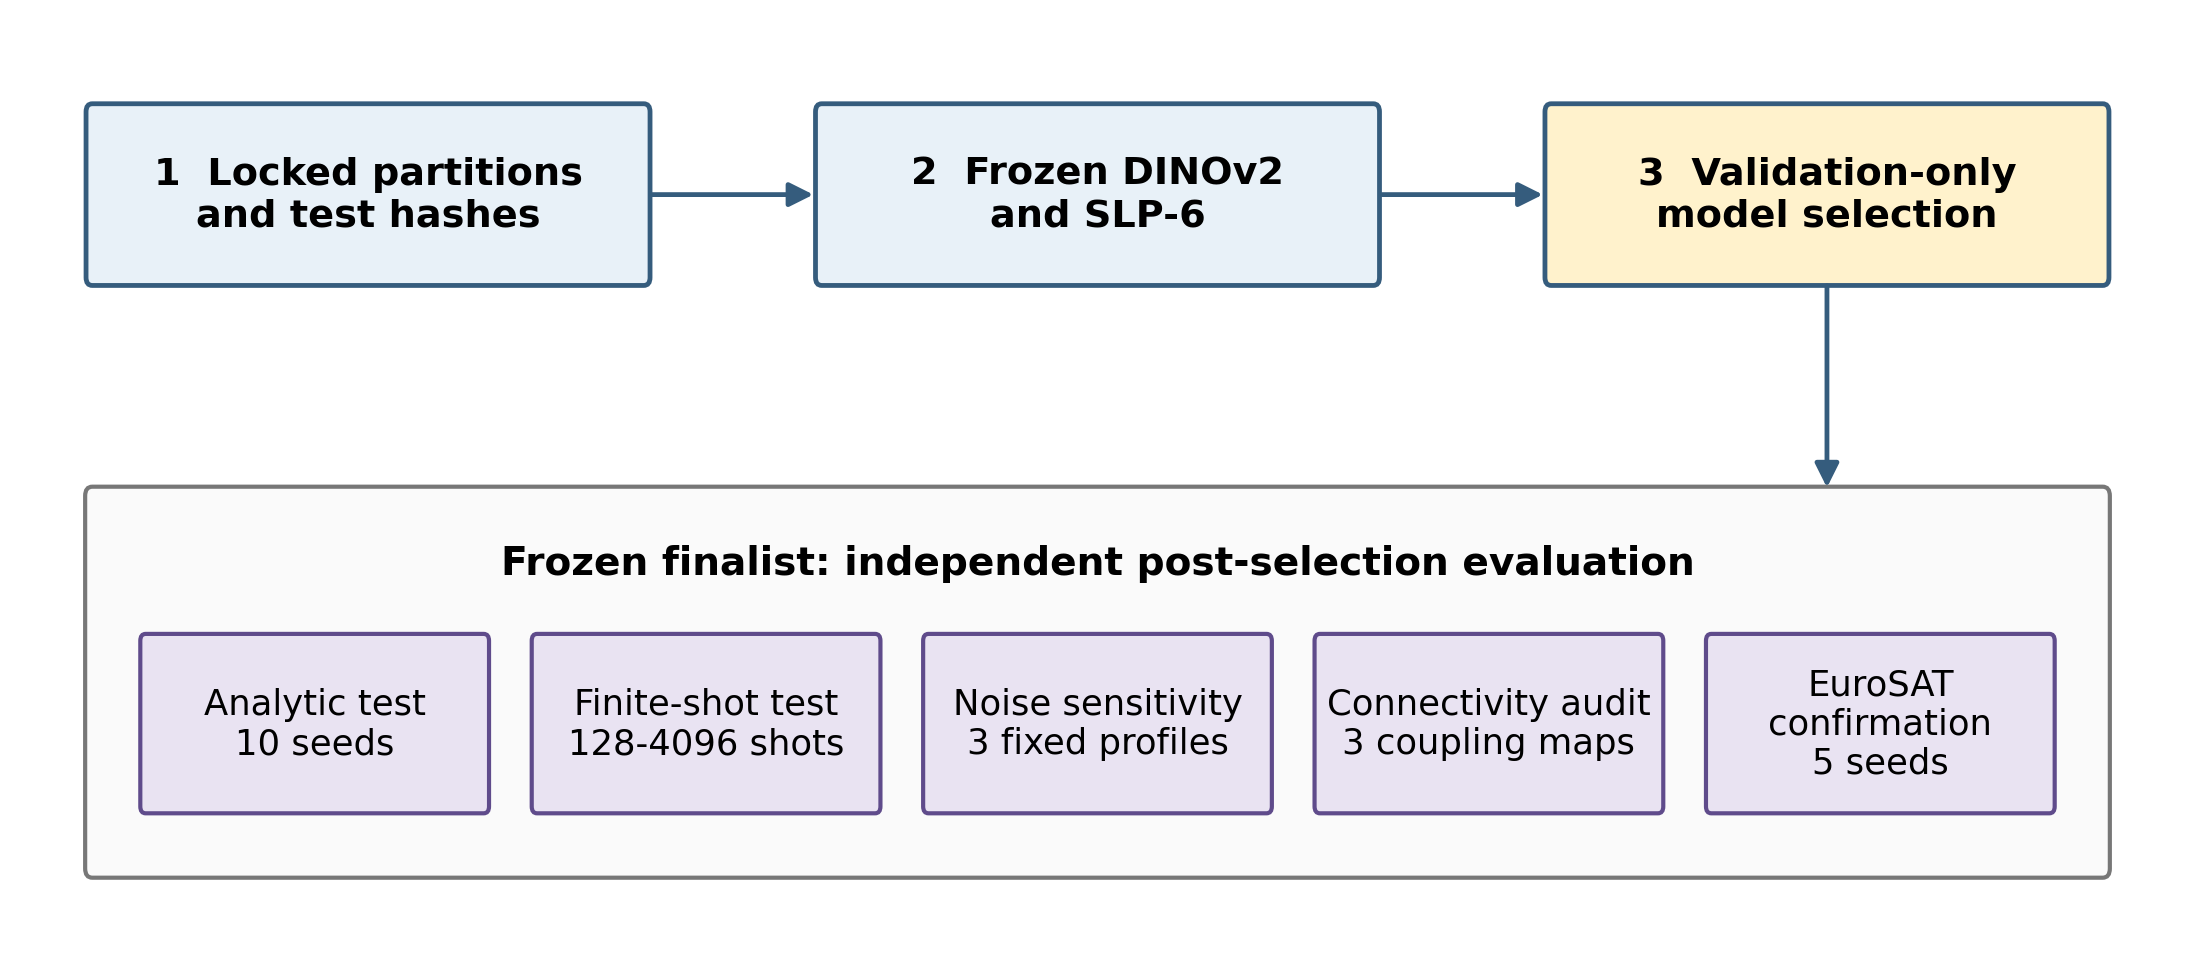

In [2]:
display(Image(filename=str(A10/'results'/'figures'/'figure_00_workflow.png')))

## Validation-only architecture screening

In [3]:
pd.read_csv(A10/'results'/'tables'/'screen_validation_summary.csv').sort_values(['dataset','macro_f1_mean'], ascending=[True,False]).groupby('dataset').head(8)

,dataset,qubits,depth,encoding,entanglement,n,macro_f1_mean,macro_f1_std,nll_mean,fit_seconds_mean,epochs_mean
11,cifar10,8,6,once,ring,5,0.917778,0.013009,0.435851,245.682659,48.8
10,cifar10,8,4,once,ring,5,0.907027,0.019309,0.485031,154.878238,41.6
7,cifar10,6,6,once,ring,5,0.900970,0.023155,0.446561,173.678500,49.6
15,cifar10,10,6,once,ring,5,0.888647,0.011559,0.557885,507.822577,64.0
6,cifar10,6,4,once,ring,5,0.887427,0.021376,0.671732,116.933298,56.0
14,cifar10,10,4,once,ring,5,0.885091,0.020347,0.614466,342.114966,63.4
5,cifar10,6,2,once,ring,5,0.879790,0.013888,0.761426,80.380217,68.8
13,cifar10,10,2,once,ring,5,0.879018,0.018579,0.804026,152.108390,51.0
27,pathmnist,8,6,once,ring,5,0.806524,0.013187,0.840538,268.842079,63.6
23,pathmnist,6,6,once,ring,5,0.790055,0.021440,0.827120,186.371188,58.4


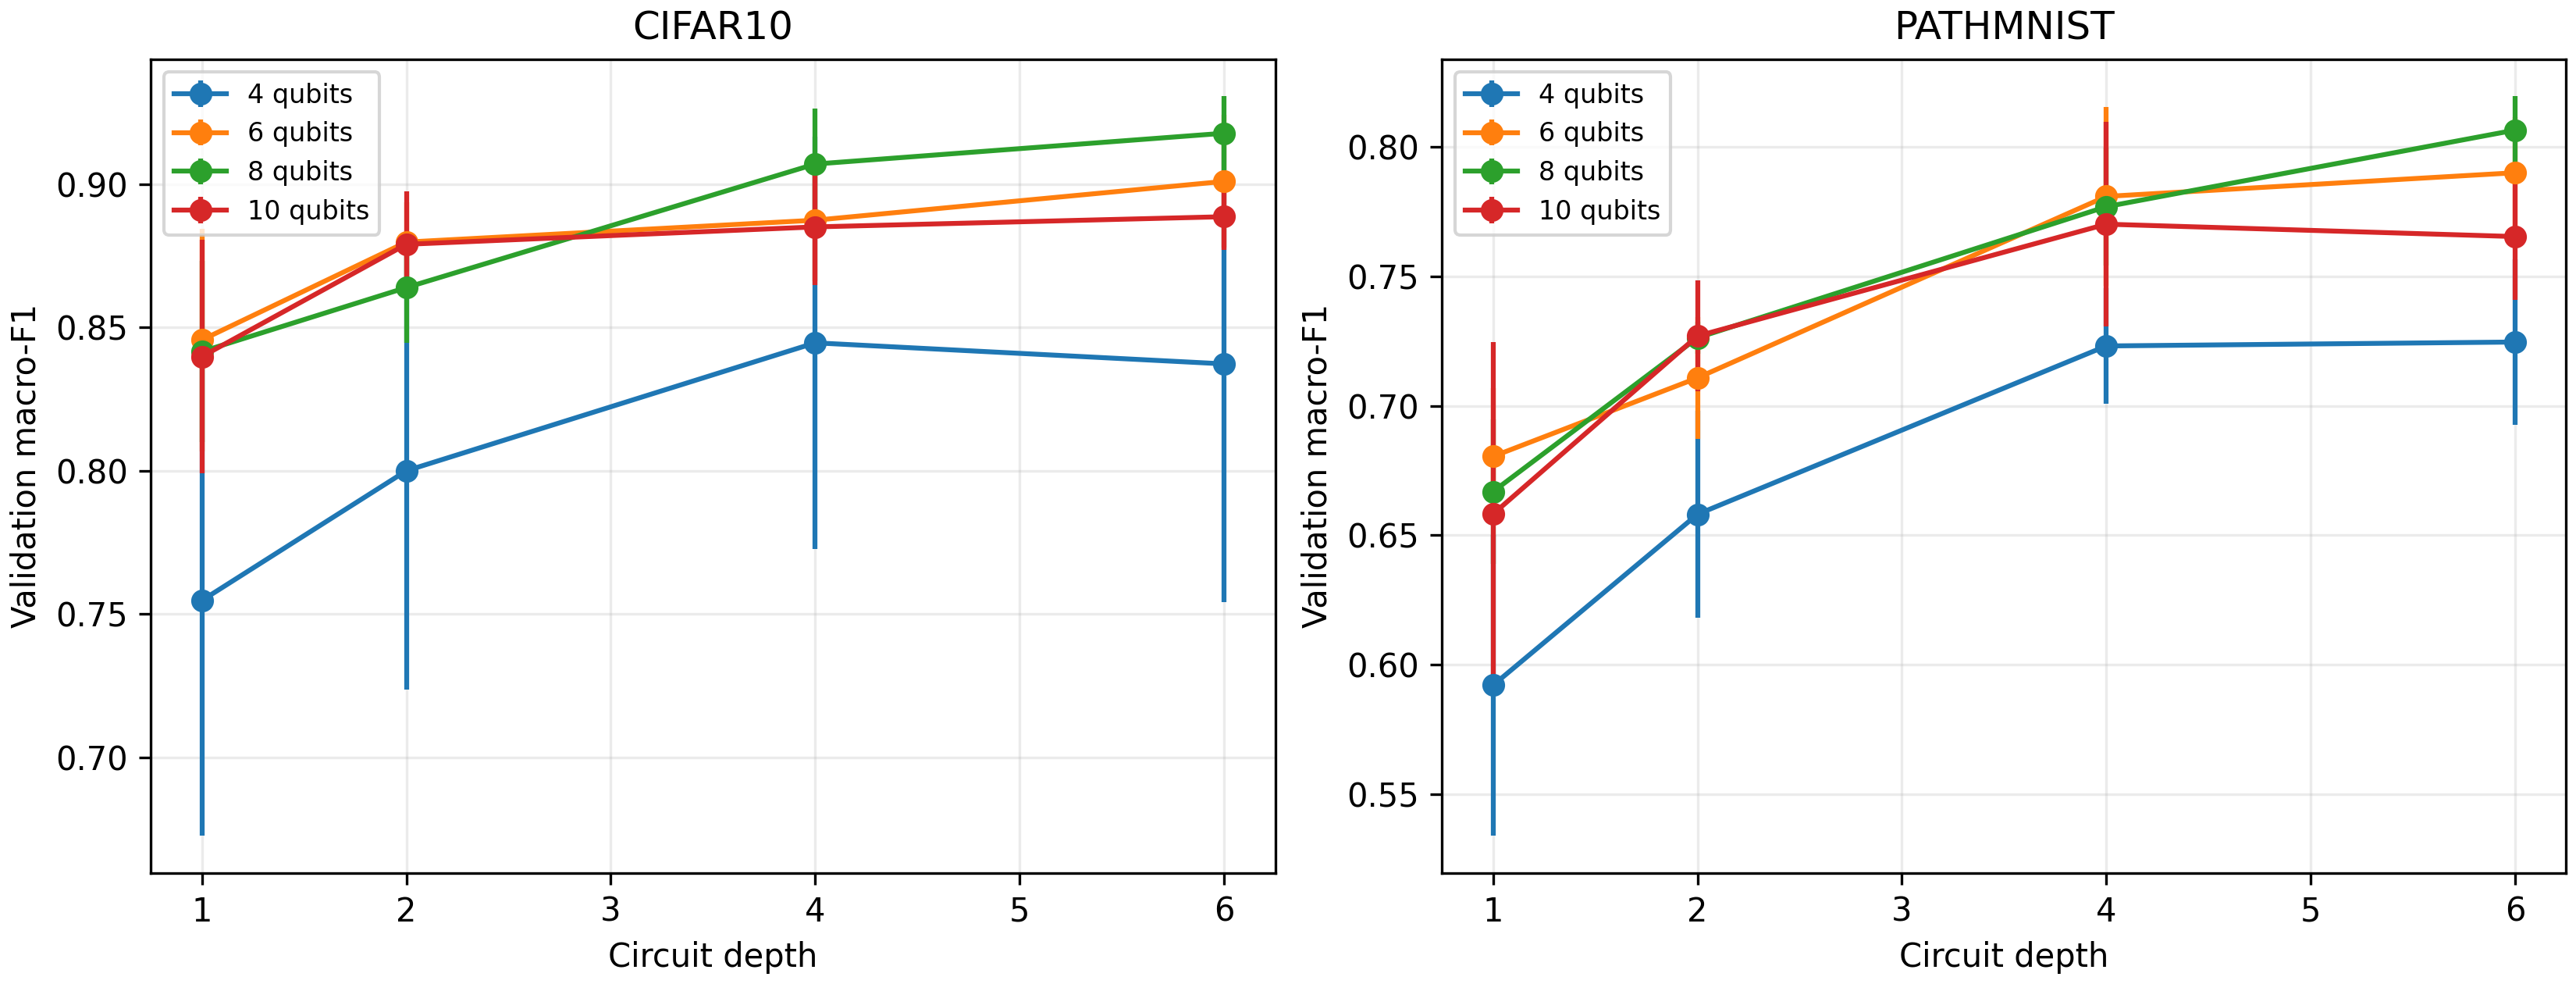

In [4]:
display(Image(filename=str(A10/'results'/'figures'/'figure_01_width_depth_scaling.png')))

## Ten-seed finalists

In [5]:
pd.read_csv(A10/'results'/'tables'/'final_validation_summary.csv')

,dataset,qubits,depth,encoding,entanglement,n,macro_f1_mean,macro_f1_std,nll_mean,fit_seconds_mean,epochs_mean
0,cifar10,8,4,once,linear,10,0.925469,0.007548,0.414298,112.169199,42.5
1,pathmnist,8,6,once,linear,10,0.810768,0.011729,0.801098,222.141786,52.4


## Finite-shot robustness with seed-level bootstrap intervals

In [6]:
pd.read_csv(A10/'results'/'tables'/'finite_shot_summary_with_ci.csv')

,dataset,shots,seeds,macro_f1_mean,macro_f1_std,macro_f1_ci95_low,macro_f1_ci95_high,accuracy_mean,accuracy_std,accuracy_ci95_low,...,brier_ci95_low,brier_ci95_high,probability_drift_mean,probability_drift_std,probability_drift_ci95_low,probability_drift_ci95_high,label_flip_rate_mean,label_flip_rate_std,label_flip_rate_ci95_low,label_flip_rate_ci95_high
0,cifar10,1024,10,0.914414,0.007060,0.910195,0.918376,0.914440,0.006937,0.910285,...,0.133279,0.149955,0.001135,0.000322,0.000964,0.001341,0.003228,0.001095,0.002670,0.003924
1,cifar10,128,10,0.913716,0.007104,0.909397,0.917726,0.913758,0.006988,0.909491,...,0.134452,0.151506,0.003341,0.000936,0.002845,0.003930,0.009055,0.003088,0.007541,0.011075
2,cifar10,4096,10,0.914546,0.006968,0.910485,0.918547,0.914566,0.006848,0.910573,...,0.132903,0.149639,0.000565,0.000161,0.000481,0.000667,0.001654,0.000636,0.001322,0.002059
3,cifar10,512,10,0.914288,0.007074,0.910100,0.918358,0.914316,0.006950,0.910212,...,0.133227,0.150074,0.001616,0.000458,0.001373,0.001917,0.004599,0.001622,0.003781,0.005626
4,cifar10,analytic,10,0.914506,0.006905,0.910436,0.918399,0.914527,0.006781,0.910545,...,0.133037,0.149588,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
5,eurosat,1024,5,0.840029,0.009044,0.833204,0.847760,0.844711,0.009084,0.837452,...,0.234288,0.257925,0.001858,0.000359,0.001638,0.002178,0.007455,0.001365,0.006329,0.008467
6,eurosat,128,5,0.838809,0.009050,0.832403,0.846790,0.843521,0.009068,0.836800,...,0.236858,0.259737,0.005388,0.001087,0.004726,0.006358,0.021103,0.004394,0.018077,0.024989
7,eurosat,4096,5,0.840438,0.008984,0.833571,0.848169,0.845101,0.009030,0.837776,...,0.234506,0.257635,0.000928,0.000181,0.000817,0.001090,0.003821,0.000862,0.003156,0.004486
8,eurosat,512,5,0.839824,0.009160,0.833048,0.847679,0.844517,0.009176,0.837506,...,0.235290,0.257778,0.002632,0.000506,0.002316,0.003079,0.010596,0.002078,0.008854,0.012311
9,eurosat,analytic,5,0.840567,0.008729,0.833727,0.848128,0.845235,0.008784,0.838025,...,0.233917,0.257567,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000


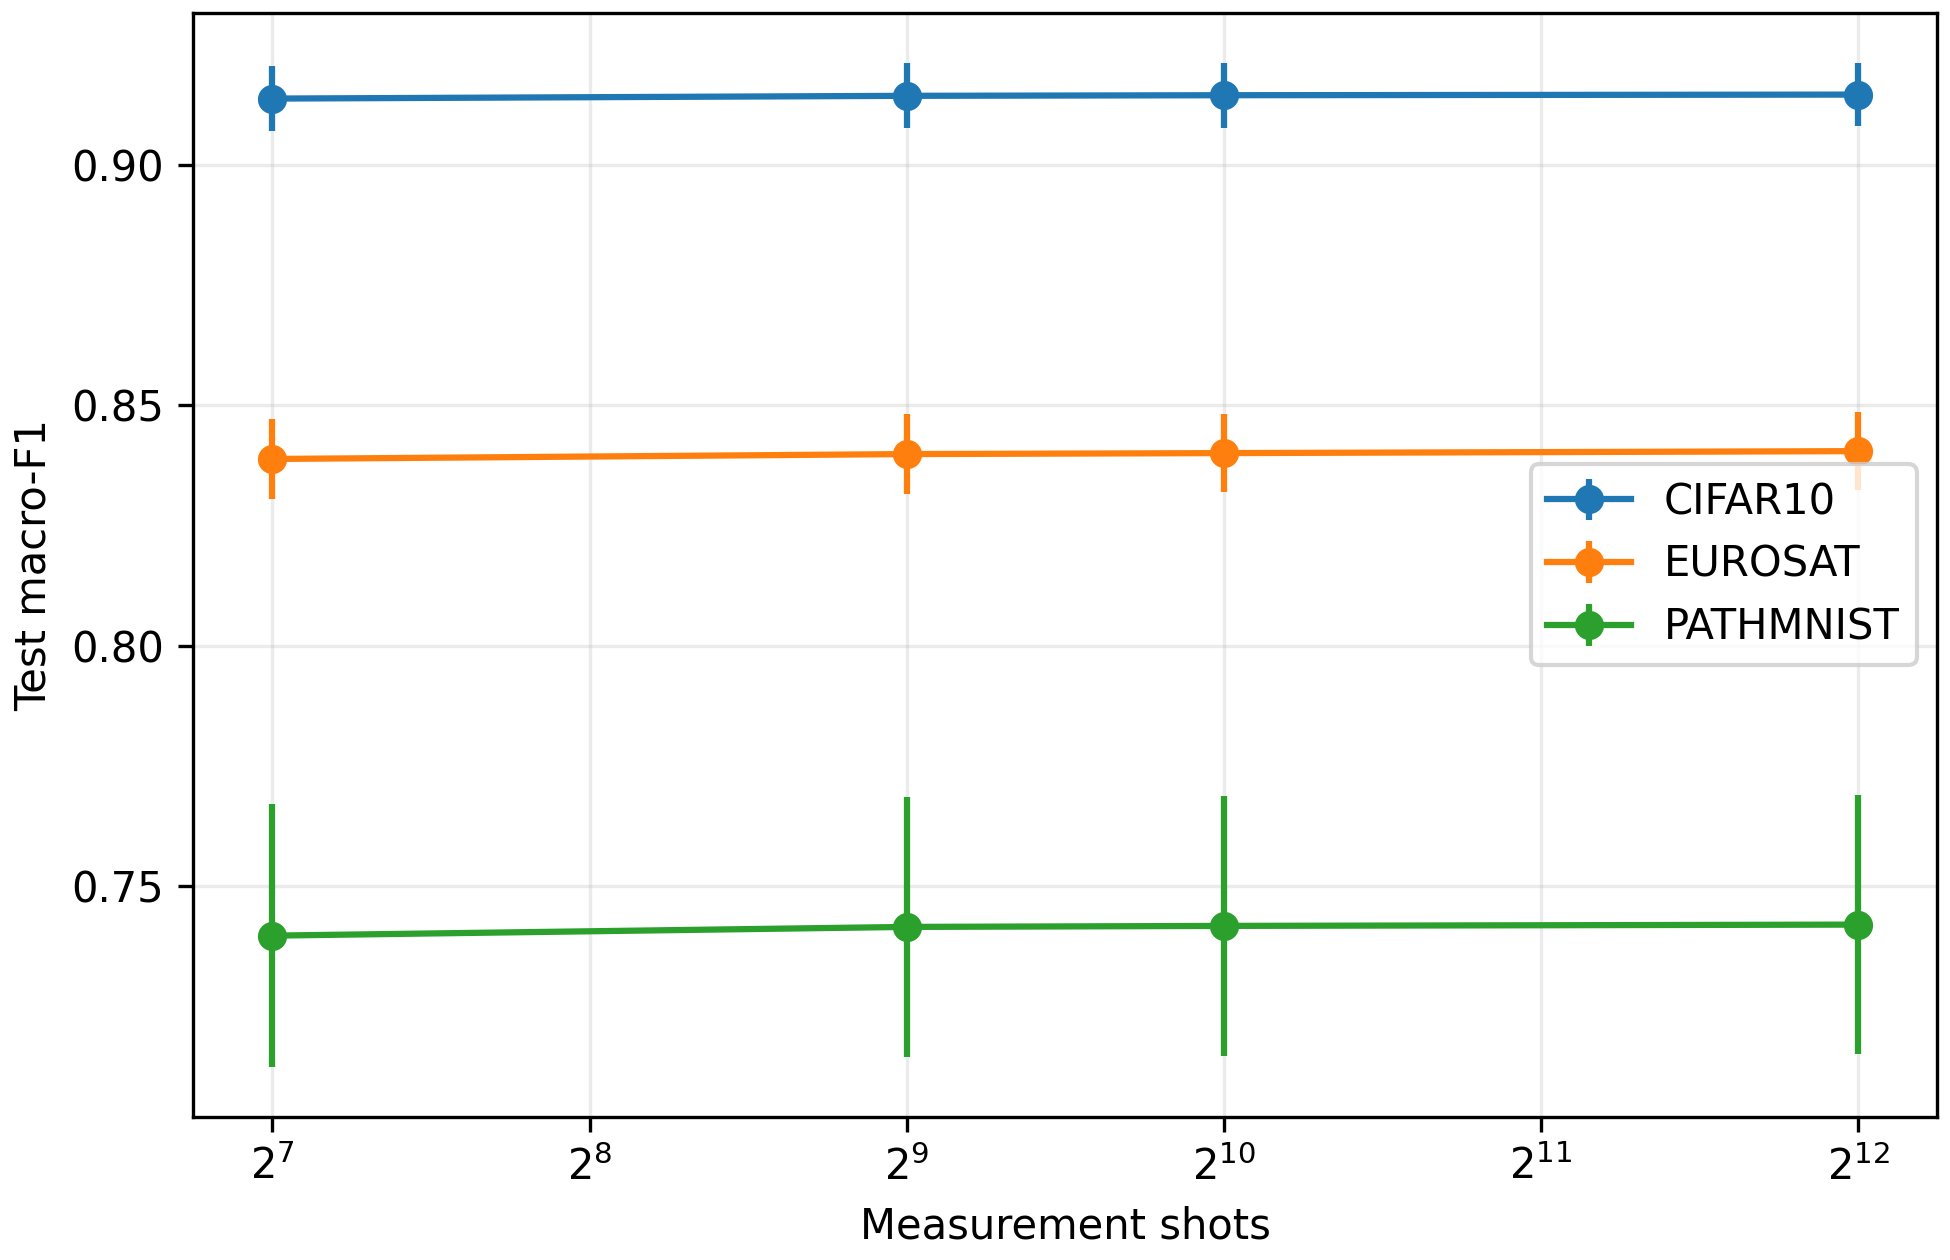

In [7]:
display(Image(filename=str(A10/'results'/'figures'/'figure_02_finite_shots.png')))

## Circuit-level depolarizing and readout noise

In [8]:
pd.read_csv(A10/'results'/'tables'/'noise_degradation_summary.csv').query("split == 'test'")

,dataset,split,profile,seed,samples,probability_drift,label_flip_rate,macro_f1,balanced_accuracy,accuracy,...,ece,brier,analytic_macro_f1,analytic_nll,analytic_ece,analytic_brier,delta_macro_f1,delta_nll,delta_ece,delta_brier
3,cifar10,test,mild,99,1000,0.005191,0.004000,0.904787,0.905000,0.905000,...,0.056761,0.152998,0.904800,0.392816,0.039808,0.154018,-0.000013,-0.000877,0.016953,-0.001020
4,cifar10,test,medium,99,1000,0.011643,0.005000,0.904795,0.905000,0.905000,...,0.085155,0.153151,0.904800,0.392816,0.039808,0.154018,-0.000005,0.006645,0.045347,-0.000867
5,cifar10,test,high,99,1000,0.029058,0.008000,0.905743,0.906000,0.906000,...,0.143692,0.171917,0.904800,0.392816,0.039808,0.154018,0.000943,0.069411,0.103884,0.017899
9,pathmnist,test,mild,33,900,0.009261,0.016667,0.764015,0.768889,0.768889,...,0.103866,0.382371,0.763197,1.176256,0.137276,0.387052,0.000818,-0.117884,-0.033410,-0.004681
10,pathmnist,test,medium,33,900,0.020210,0.034444,0.761569,0.765556,0.765556,...,0.068019,0.383693,0.763197,1.176256,0.137276,0.387052,-0.001628,-0.190596,-0.069257,-0.003359
11,pathmnist,test,high,33,900,0.048376,0.083333,0.738185,0.737778,0.737778,...,0.079553,0.421815,0.763197,1.176256,0.137276,0.387052,-0.025012,-0.210197,-0.057723,0.034764
15,eurosat,test,mild,55,1000,0.006951,0.016000,0.835253,0.836000,0.836000,...,0.059343,0.255719,0.831518,0.762244,0.086170,0.262218,0.003735,-0.062493,-0.026827,-0.006498
16,eurosat,test,medium,55,1000,0.015007,0.035000,0.834417,0.835000,0.835000,...,0.046334,0.255440,0.831518,0.762244,0.086170,0.262218,0.002899,-0.096928,-0.039836,-0.006778
17,eurosat,test,high,55,1000,0.038362,0.073000,0.824800,0.824000,0.824000,...,0.087927,0.292111,0.831518,0.762244,0.086170,0.262218,-0.006718,-0.055661,0.001756,0.029894


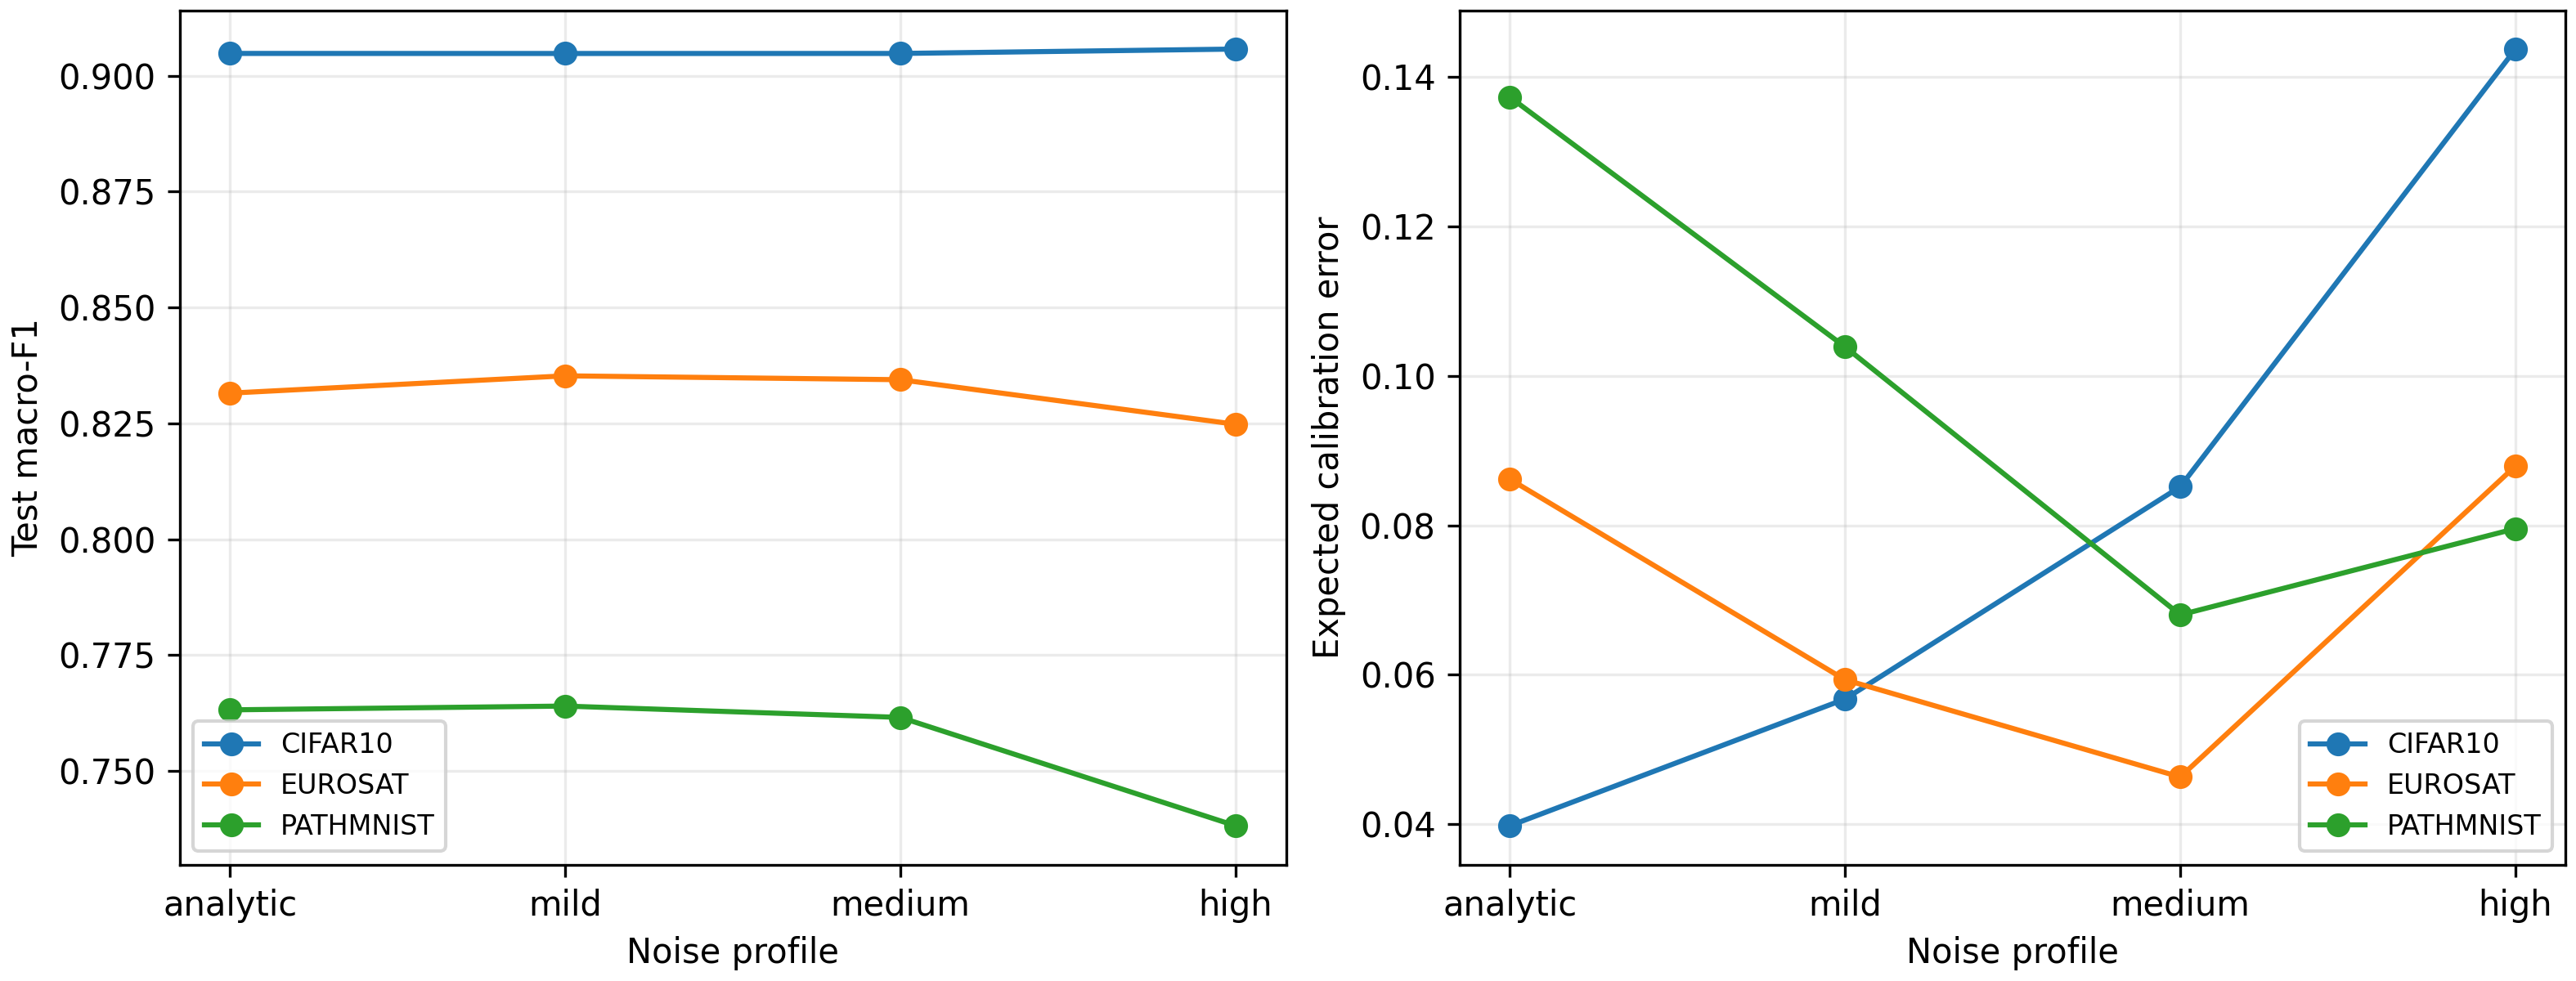

In [9]:
display(Image(filename=str(A10/'results'/'figures'/'figure_03_noise_sensitivity.png')))

## Connectivity-aware transpilation

In [10]:
pd.read_csv(A10/'results'/'tables'/'transpilation_metrics.csv').query("qubits == 8 and topology == 'linear'")

,qubits,depth,encoding,entanglement,topology,logical_depth,transpiled_depth,two_qubit_gates,swap_count,size,ops_json
50,8,1,once,linear,linear,11,7,7,0,7,"{""cx"": 7}"
53,8,1,once,ring,linear,12,13,8,6,14,"{""cx"": 8, ""swap"": 6}"
56,8,2,once,linear,linear,16,9,14,0,14,"{""cx"": 14}"
59,8,2,once,ring,linear,23,27,16,14,30,"{""cx"": 16, ""swap"": 14}"
62,8,4,once,linear,linear,26,13,28,0,28,"{""cx"": 28}"
65,8,4,once,ring,linear,45,56,32,34,66,"{""cx"": 32, ""swap"": 34}"
68,8,6,once,linear,linear,36,17,42,0,42,"{""cx"": 42}"
71,8,6,once,ring,linear,67,85,48,60,108,"{""cx"": 48, ""swap"": 60}"


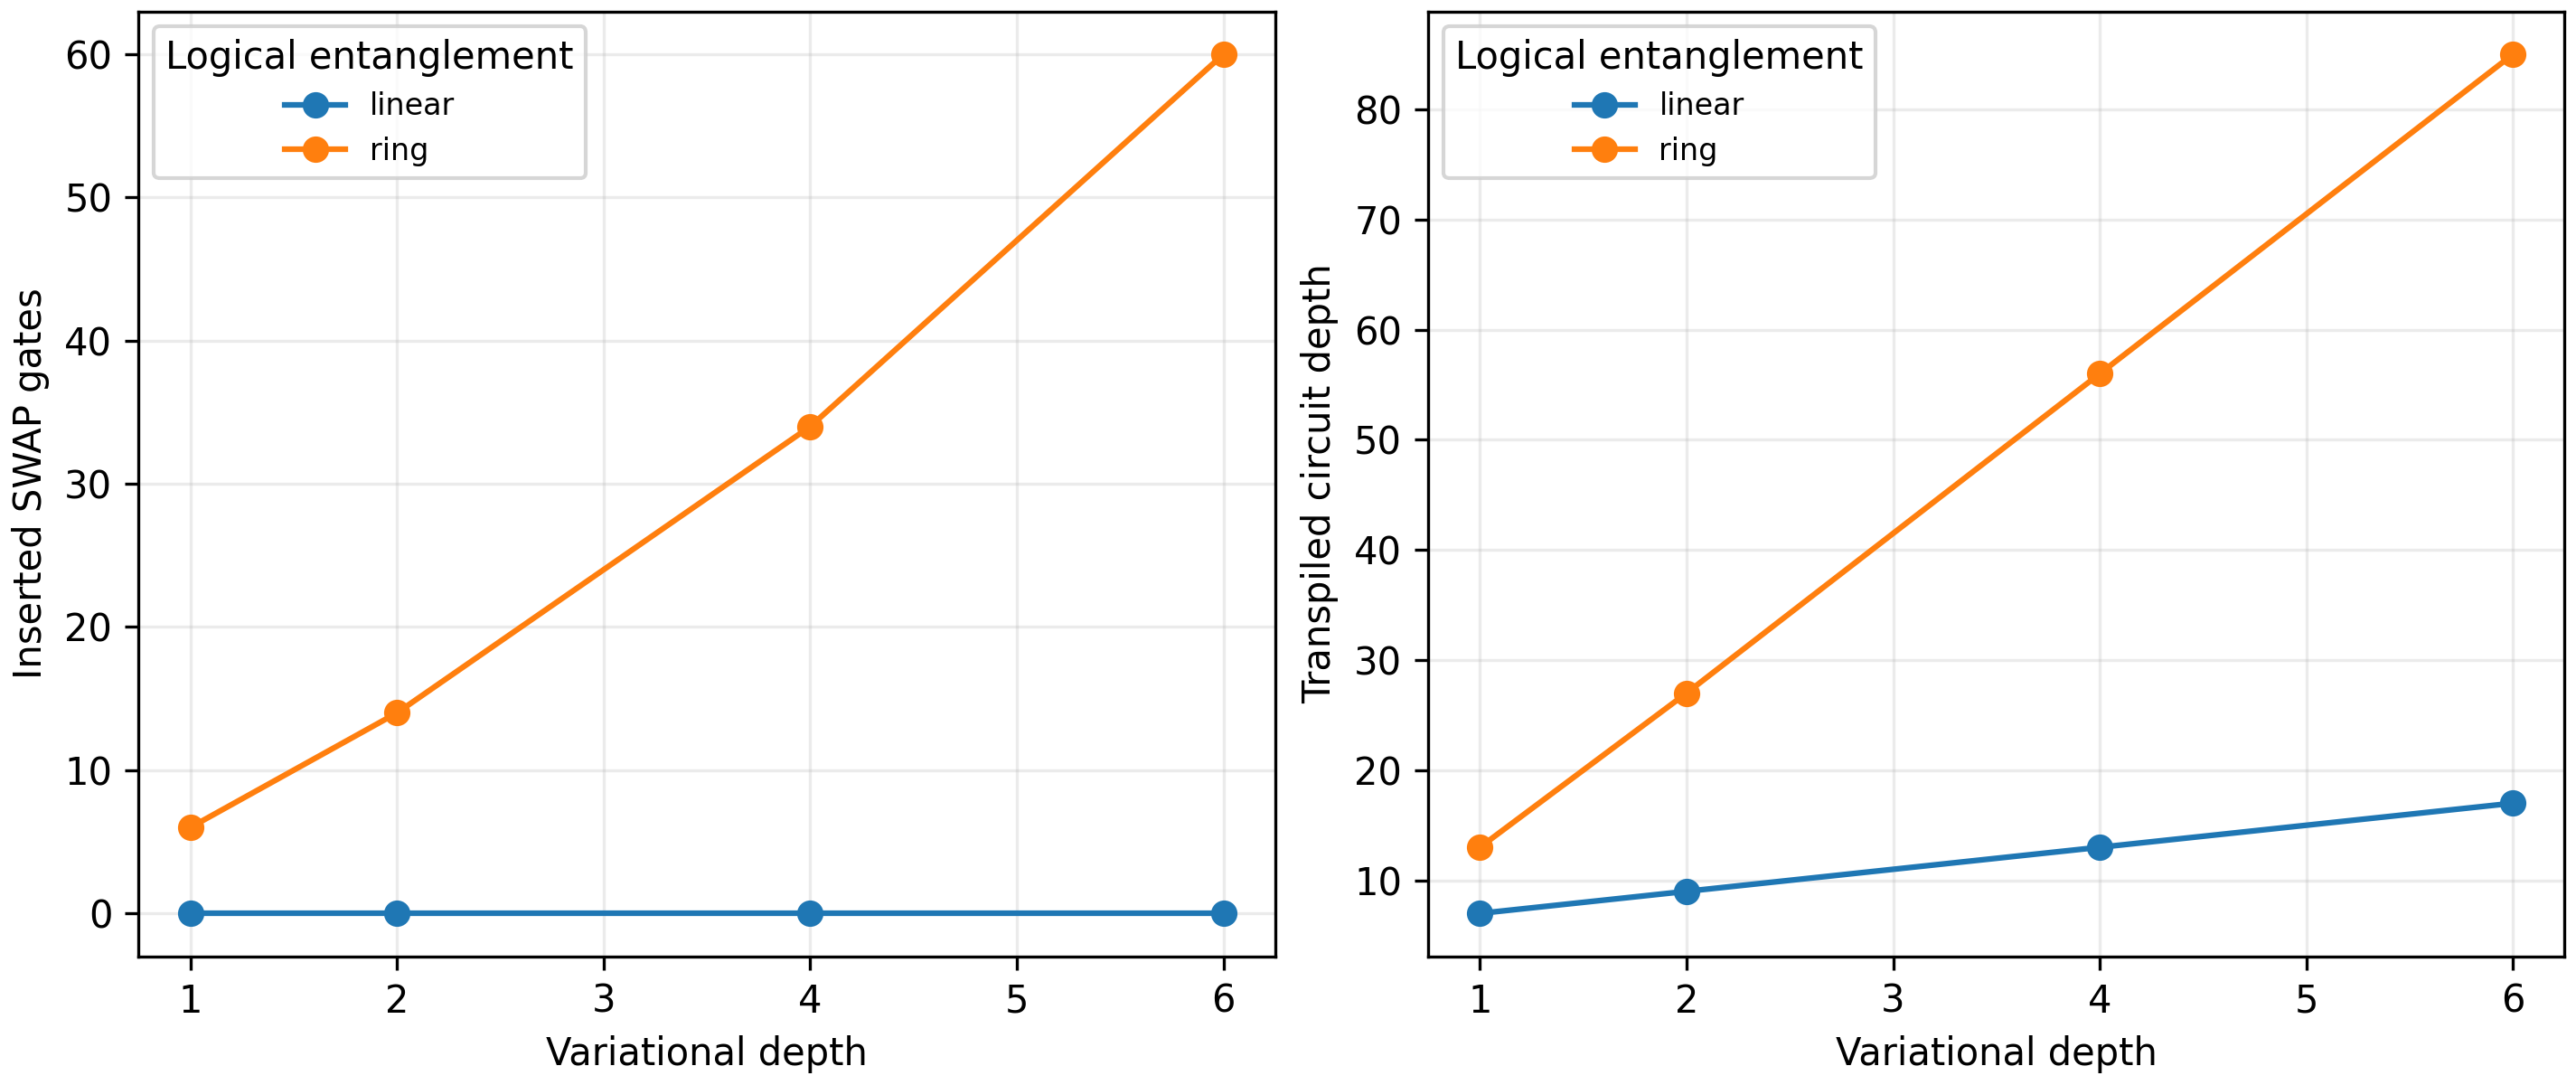

In [11]:
display(Image(filename=str(A10/'results'/'figures'/'figure_04_connectivity_overhead.png')))

## Trainability diagnostics

In [12]:
pd.read_csv(A10/'results'/'tables'/'trainability_summary.csv')

,dataset,qubits,depth,n,epochs_mean,grad_norm_epoch1_mean,grad_var_epoch1_mean,grad_norm_median_mean,best_val_mean
0,cifar10,4,1,5,44.8,0.261684,0.001140,0.348116,0.754727
1,cifar10,4,2,5,58.2,0.287750,0.001141,0.327776,0.799977
2,cifar10,4,4,5,55.8,0.341721,0.001225,0.270124,0.844632
3,cifar10,4,6,5,58.8,0.325212,0.000887,0.318430,0.837285
4,cifar10,6,1,5,59.4,0.249286,0.000735,0.371725,0.845650
5,cifar10,6,2,5,68.8,0.248962,0.000601,0.284679,0.879790
6,cifar10,6,4,5,56.0,0.244950,0.000434,0.221241,0.887427
7,cifar10,6,6,5,49.6,0.269667,0.000420,0.197052,0.900970
8,cifar10,8,1,5,57.6,0.262765,0.000624,0.391361,0.841584
9,cifar10,8,2,5,54.2,0.268974,0.000541,0.307544,0.863922


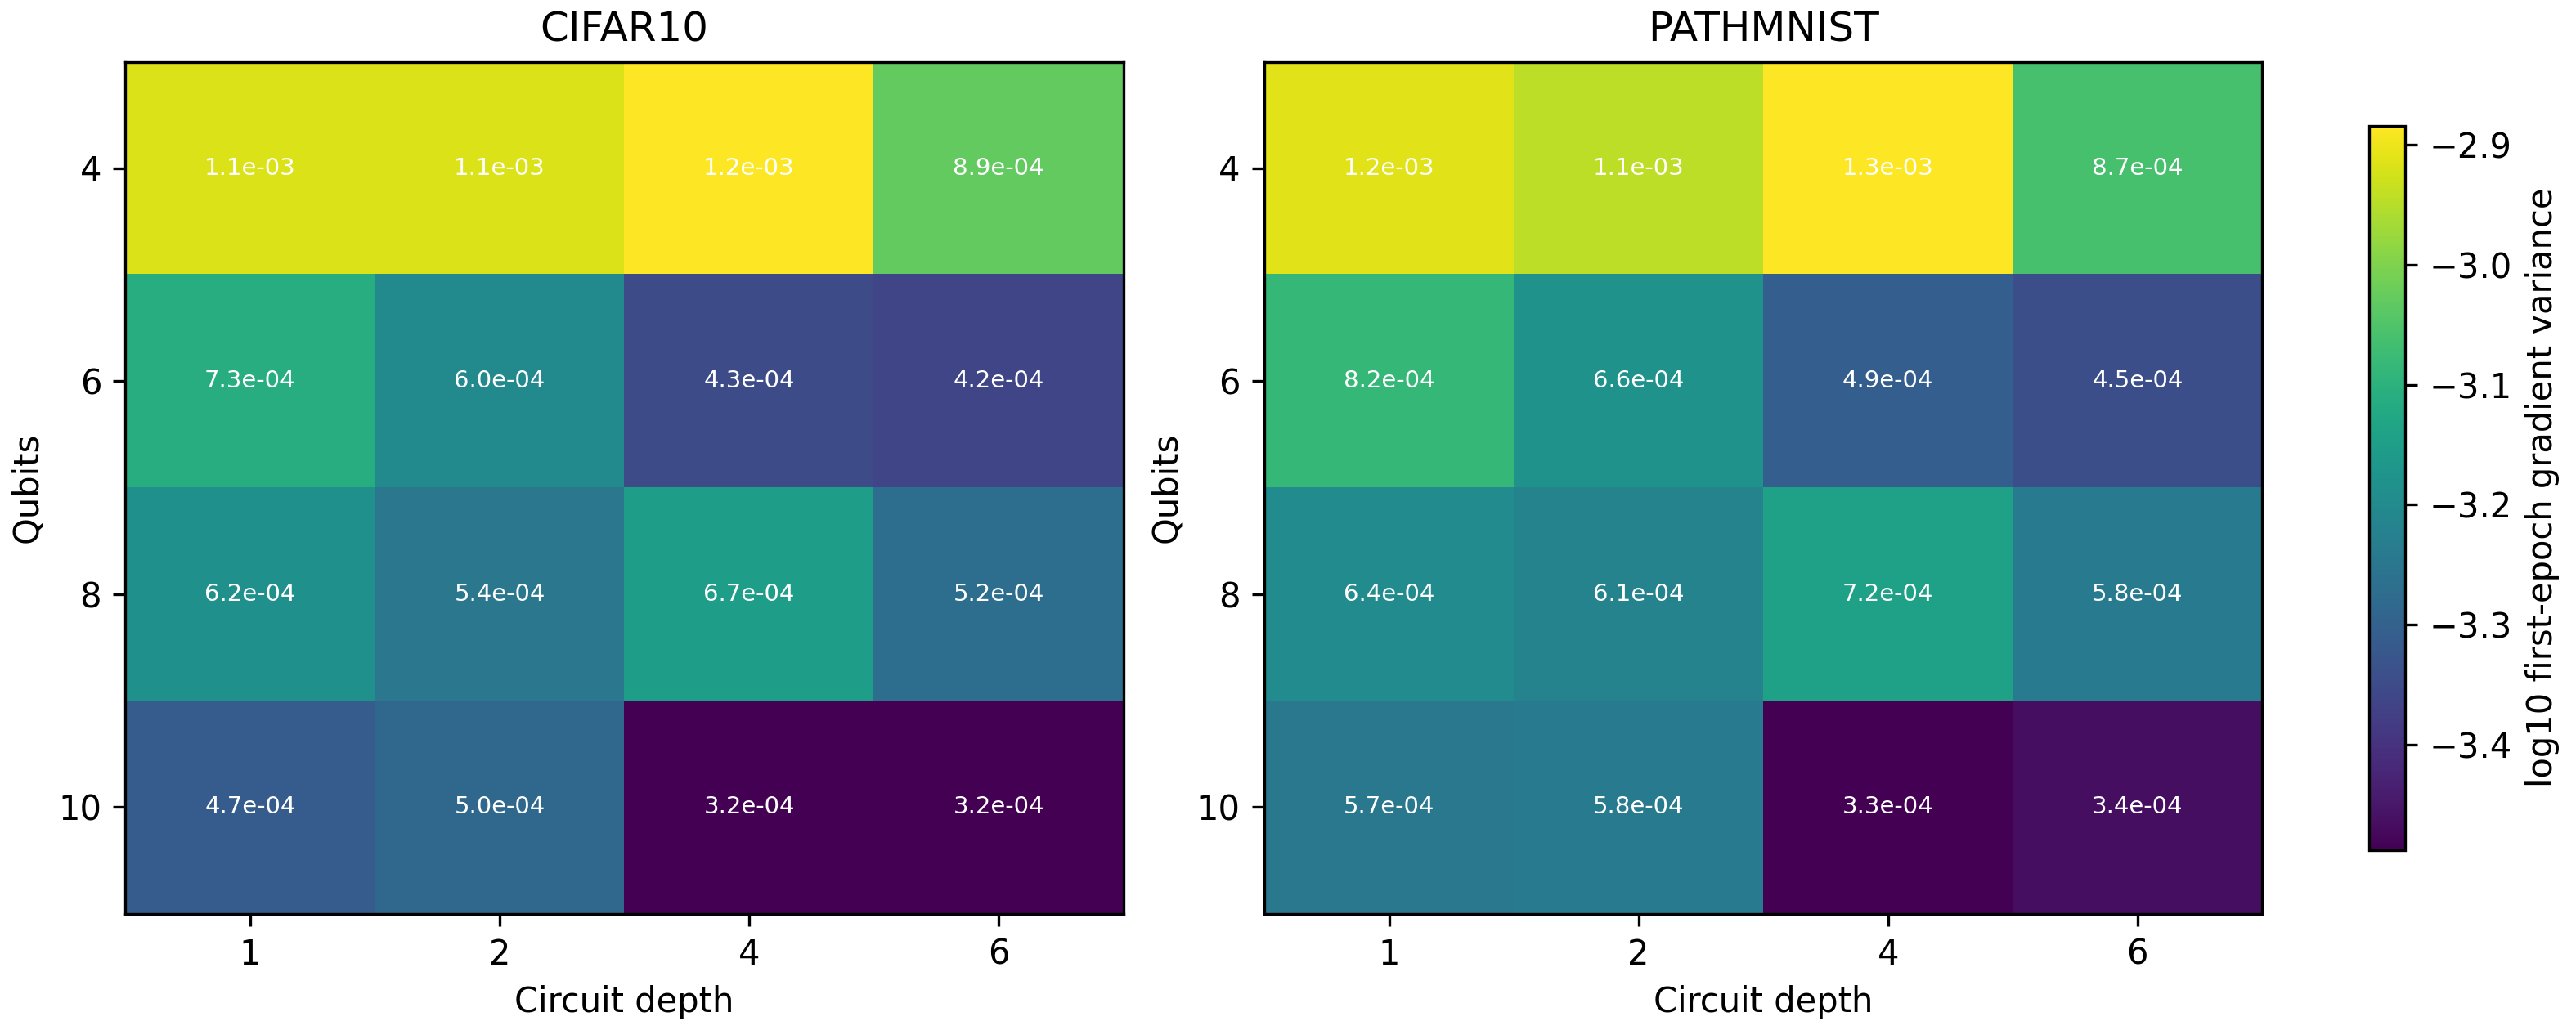

In [13]:
display(Image(filename=str(A10/'results'/'figures'/'figure_05_trainability.png')))

## Re-run instructions

Use `python run_article10.py --stage all --resume`. Set `ARTICLE09_ROOT` to an Article 9 workspace containing the immutable embeddings and fitted SLP-6 representations. Real-hardware execution remains disabled unless separately authorized.